# Damped Pendulum Analysis: Baseline Scenario

**Prepared by:** Adrien Dumont
**Course:** ENSC 201 Programming for Engineers, Fall 2026
**Date:** November 24, 2026

## Section 1: Executive Summary & Governing Physics

**Executive summary.** For this PA8 Assignment, I simulated a 1 m pendulum released from rest at 30° with a small amount of friction slowing it down on every time step. The swings shrink steadily, and the pendulum is considered settled after about 89 seconds, by which point it has completed 44 full swings. The main takeaway is that even a very small per-step friction loss (0.1% of the speed every 0.01 s) is enough to bring the pendulum essentially to rest in under a minute and a half.

### Governing Physics

| Symbol | Meaning | Units |
|---|---|---|
| $\theta$ | Angle from vertical (stored in radians; plots use degrees) | rad |
| $\theta_0$ | Initial (release) angle | degrees in the parameter file |
| $\omega$ | Angular velocity | rad/s |
| $\alpha$ | Angular acceleration | rad/s² |
| $g$ | Gravitational acceleration | m/s² |
| $L$ | Pendulum length | m |
| $\Delta t$ | Time step | s |
| $n$ | Step number (time $t_n = n\,\Delta t$) | unitless |
| $c$ | Friction coefficient (per-step velocity multiplier) | unitless |
| $\omega_{\min}$ | Minimum angular-velocity threshold | rad/s |

The pendulum is released from rest ($\theta_0$, $\omega_0 = 0$) and advanced with a fixed time step $\Delta t$. Gravity provides the angular acceleration:

$$\alpha_n = -\frac{g}{L}\sin(\theta_n)$$

The angular velocity is first reduced by friction and then updated with the acceleration. The angle is updated with the **new** velocity (semi-implicit Euler):

$$\omega_{n+1} = c\,\omega_n + \alpha_n\,\Delta t$$

$$\theta_{n+1} = \theta_n + \omega_{n+1}\,\Delta t$$

**Friction as a per-step decay factor.** Because $c$ multiplies the velocity once every step, its effect compounds geometrically ($\omega \to c\,\omega \to c^2\omega \to \dots$). Ignoring gravity, after $n$ steps only $c^{\,n}$ of the velocity remains, so over one second the velocity is scaled by

$$c^{\,1/\Delta t}$$

With $c < 1$ the motion dies out; a smaller $c$ means heavier damping, and $c = 1$ means no friction.

**Threshold rule.** The simulation stops when the pendulum crosses equilibrium (the angle changes sign) **and** its speed at that crossing is small:

$$\theta_n\,\theta_{n+1} < 0 \quad\text{and}\quad |\omega_{n+1}| \le \omega_{\min}$$

If this never happens, the simulation stops at the maximum simulation time.

**Swing-counting rule.** One complete swing (over and back) passes through equilibrium twice:

$$\text{swings} = \left\lfloor \frac{\text{crossings}}{2} \right\rfloor$$

In [1]:
import matplotlib.pyplot as plt

from pendulum import (read_parameters, simulate_pendulum, plot_baseline,
                      show_summary_table)

## Section 2: Baseline Parameters & Metrics Summary

The baseline parameters are read from `pendulum_parameters.txt` (unaltered), and the simulation is run once with the functions from `pendulum.py`.

In [2]:
baseline_parameters = read_parameters("pendulum_parameters.txt")
baseline_results = simulate_pendulum(baseline_parameters)

In [3]:
show_summary_table(baseline_parameters, baseline_results)


| Parameter or Metric | Value | Units |
|---|---|---|
| Initial angle | 30 | degrees |
| Pendulum length | 1 | m |
| Gravitational acceleration | 9.81 | m/s² |
| Friction coefficient (per-step decay) | 0.999 | unitless |
| Time step | 0.01 | s |
| Maximum simulation time | 120 | s |
| Angular velocity threshold | 0.02 | rad/s |
| **Time to threshold** | **88.93** | **s** |
| **Equilibrium crossings** | **89** | **count** |
| **Completed swings** | **44** | **count** |
| **Final time** | **88.93** | **s** |
| **Stop reason** | **angular velocity at an equilibrium crossing reached the threshold** | |
| **Maximum angle magnitude** | **30.00** | **degrees** |
| **Peak angular speed** | **1.5816** | **rad/s** |
| **Final angular velocity** | **-0.0190** | **rad/s** |


**Table 1: Baseline parameters (top) and simulation results (bold).** All values are pulled directly from the parameter file and the simulation output. The threshold was reached at 88.93 s, so the run ended well before the 120 s limit; the largest angle is the 30° release angle, and the final angular velocity is just inside the 0.02 rad/s threshold.

## Section 3: Professional Multi-Chart Visualization

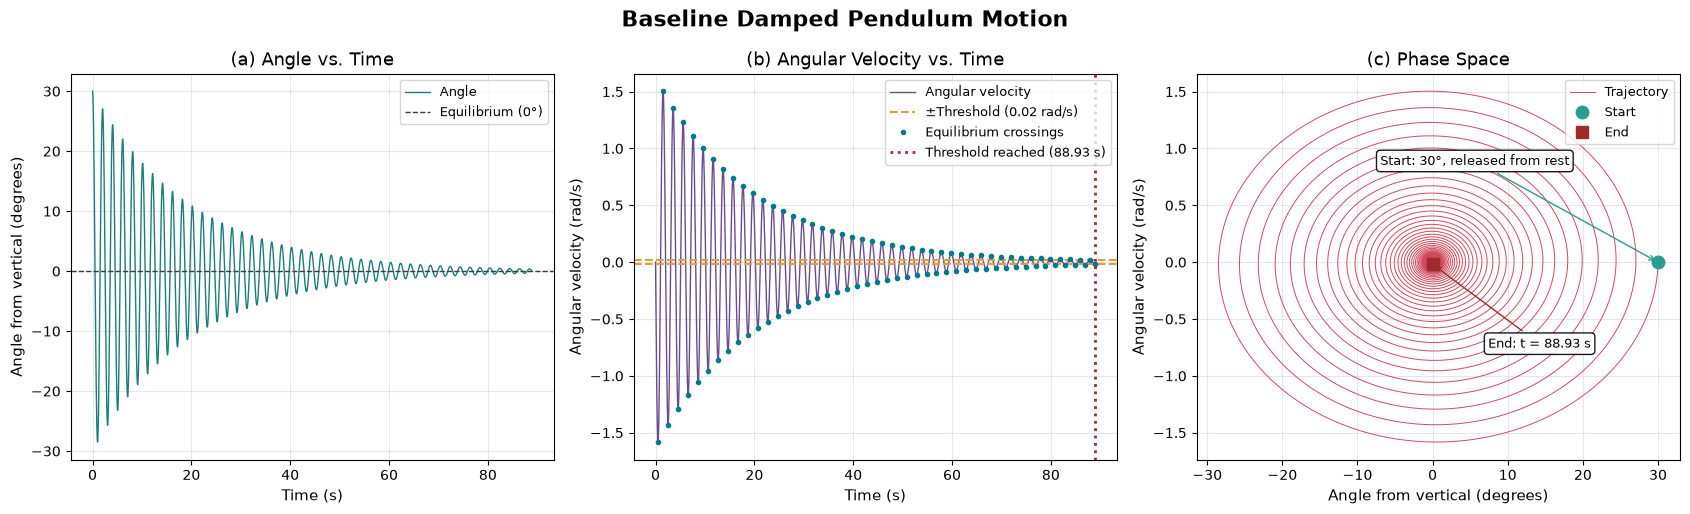

In [4]:
baseline_figure = plot_baseline(baseline_parameters, baseline_results)
plt.show()

**Figure 1: Baseline damped pendulum motion.** (a) The angle (in degrees) oscillates about the 0° equilibrium line with an amplitude that shrinks over time because of friction. (b) The angular velocity (in rad/s) decays the same way; dots mark the speed at each equilibrium crossing, and the dotted vertical line marks 88.93 s, the first crossing where the speed fell inside the ±0.02 rad/s threshold band. (c) In phase space the trajectory spirals inward from the start point (30°, at rest) toward the origin, which is what damping looks like: each loop has less energy than the one before.

## Section 4: Conclusions & Recommendations

1. **Conclusions.** The baseline pendulum settles (reaches the threshold) at **88.93 s** after **44 complete swings** (89 equilibrium crossings). The decay is driven by the friction coefficient: 0.999 per step at 100 steps per second removes about 10% of the speed every second ($0.999^{100} \approx 0.905$), so the swings shrink steadily until the crossing speed drops below 0.02 rad/s.

2. **Threshold rule.** At each turning point the pendulum momentarily stops, so its angular velocity is near zero on every single swing; checking the threshold at every step would end the simulation after the first half swing. At an equilibrium crossing the speed is at its largest for that swing, so a small value there means the pendulum has truly run out of energy.

3. **Recommendations.** To make a pendulum settle sooner, I would investigate a smaller friction coefficient $c$ (more damping, e.g., adding a damper) or a smaller release angle; to keep it swinging longer, I would look at a coefficient closer to 1 (lower-friction bearings) or a larger release angle. Each of these changes is a different parameter set and would need its own separate simulation run to evaluate; these baseline results do not predict them directly.